# Module 3 · Reading what my detector produces
This notebook uses **your** `src/evaluate.py` with the model you trained on the page *2 · Training*. Change `RUN` to the name of your run. It writes the figures your Assignment 3.2 needs.

In [1]:
import json, sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
ROOT = Path("..") if Path("../src").exists() else Path(".")
sys.path.insert(0, str(ROOT))
from src import data as dt, evaluate as ev

RUN = "detect/runs/all_e30_s416_colab"                       # the name of your training run
project = dt.load_project(ROOT / "project.yaml")
classes = project["classes"]
data_root = ROOT / "data" / f"{project['name']}_yolo"
weights = ROOT / "runs" / RUN / "weights" / "best.pt"
yaml_path = data_root / "data.yaml"
(ROOT / "results").mkdir(exist_ok=True)
print(weights, weights.exists())

..\runs\detect\runs\all_e30_s416_colab\weights\best.pt True


## 1. The score on photos the model never saw
mAP goes through all the confidence values, so it has no threshold of its own.

In [2]:
metrics = ev.yolo_metrics(weights, yaml_path)
print(json.dumps(metrics, indent=1))

Ultralytics 8.4.188  Python-3.12.1 torch-2.2.2+cpu CPU (Intel Core i5-10300H 2.50GHz)


YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs


WARNING val: Slow image access detected (ping: 0.1±0.1 ms, read: 4.0±3.2 MB/s, size: 45.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning C:\Users\TUF\OneDrive\Desktop\my-detector\MAI630_Project_Starter\data\plastic_bottles_yolo\labels\test.cache... 700 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 700/700  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/44 4.7s/it 1.4s<3:22

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ╸─────────── 2/44 2.7s/it 2.7s<1:52

... (41 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 1.4s/it 1:00

                   all        700       1215      0.858      0.683      0.778      0.635


Speed: 1.5ms preprocess, 64.3ms inference, 0.0ms loss, 1.0ms postprocess per image


{
 "mAP50": 0.7784196859873767,
 "mAP50_95": 0.6354557679344545,
 "per_class": {
  "plastic-bottle": 0.7784196859873767
 }
}


## 2. The same photos at four thresholds

conf 0.10 · TP  969 · FP 1056 · FN  246 · precision 0.48 · recall 0.80
conf 0.25 · TP  911 · FP  323 · FN  304 · precision 0.74 · recall 0.75
conf 0.50 · TP  807 · FP   93 · FN  408 · precision 0.90 · recall 0.66
conf 0.75 · TP  695 · FP   24 · FN  520 · precision 0.97 · recall 0.57
from 0.25 to 0.75: {'removed_correct': 216, 'removed_wrong': 299}


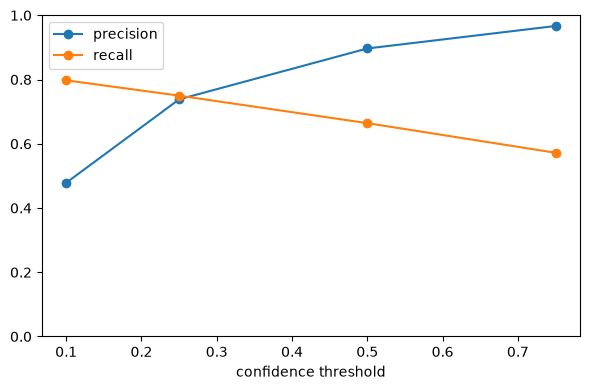

In [3]:
images = ev.predict_images(weights, data_root / "images" / "test", data_root / "labels" / "test", classes)
table = ev.threshold_table(images)
for r in table:
    print(f"conf {r['conf']:.2f} · TP {r['tp']:4d} · FP {r['fp']:4d} · FN {r['fn']:4d} · precision {r['precision']:.2f} · recall {r['recall']:.2f}")
print("from 0.25 to 0.75:", ev.what_changed(images, 0.25, 0.75))
json.dump(table, open(ROOT / "results" / "thresholds.json", "w"), indent=1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([r["conf"] for r in table], [r["precision"] for r in table], "-o", label="precision")
ax.plot([r["conf"] for r in table], [r["recall"] for r in table], "-o", label="recall")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1); ax.legend(); fig.tight_layout()
fig.savefig(ROOT / "results" / "thresholds.png", dpi=150); plt.show()

## 3. Look at the images
Green: correct. Red: false alarm. Yellow: an object the detector missed.

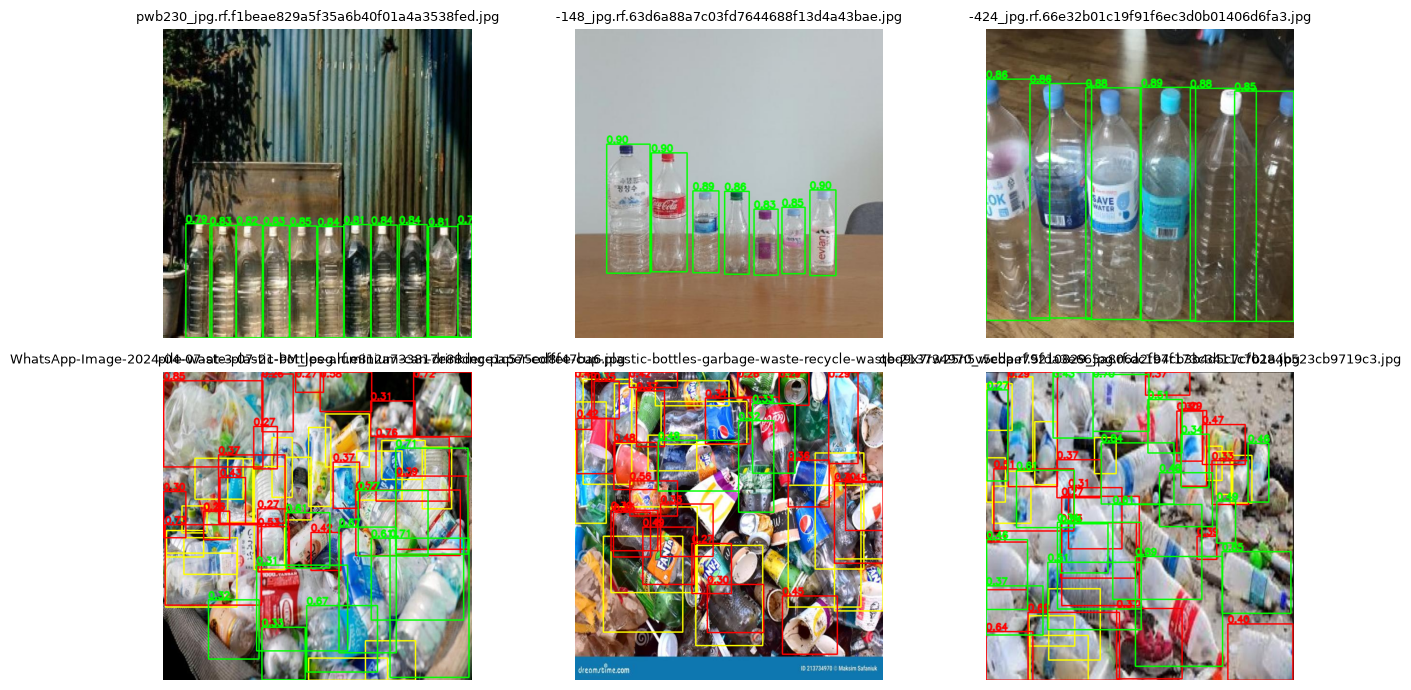

{'correct': ['pwb230_jpg.rf.f1beae829a5f35a6b40f01a4a3538fed.jpg', '-148_jpg.rf.63d6a88a7c03fd7644688f13d4a43bae.jpg', '-424_jpg.rf.66e32b01c19f91f6ec3d0b01406d6fa3.jpg'], 'wrong': ['WhatsApp-Image-2024-04-07-at-3-07-21-PM_jpeg.rf.e812a733817e88dece1c575ed8f47ba6.jpg', 'pile-waste-plastic-bottles-aluminium-can-drinking-paper-coffee-cup-plastic-bottles-garbage-waste-recycle-waste-213734970_webp.rf.5fda3e665a806a2f97f173c3411c7b1a.jpg', 'qbq9x7rw25n5v5cdae79210829_jpg.rf.dc1b4cb3b4d5c7cf0284b523cb9719c3.jpg']}


In [4]:
def panel(name):
    rgb = cv2.cvtColor(cv2.imread(str(data_root / "images" / "test" / name)), cv2.COLOR_BGR2RGB)
    d = images[name]
    return ev.draw_result(rgb, ev.match([p for p in d["preds"] if p["score"] >= 0.25], d["truths"]))
picked = ev.pick_examples(images, conf=0.25, n=3)
names = picked["correct"] + picked["wrong"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, n in zip(axes.flat, names):
    ax.imshow(panel(n)); ax.set_title(n, fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ROOT / "results" / "examples.png", dpi=150); plt.show()
print(picked)

## 4. Now it is your turn
Ask the subagent `image-auditor` to look at `results/examples.png`, and `metrics-reviewer` to read your draft. They point things out. **The interpretation is yours.**